In [1]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
import rasterio
from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [2]:
DATA_PATH = "../dataset/bundle/aviris_hyperspectral_data/19920612_AVIRIS_IndianPine_Site3.tif"
GT_PATH = "../dataset/bundle/aviris_hyperspectral_data/Indian_pines_gt.mat"

c:\Users\Ammar\OneDrive\Dokumen\Belajar\HSICV\hsicv\Lib\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Width: 145
Height: 145
Bands: 220
Data type: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uin

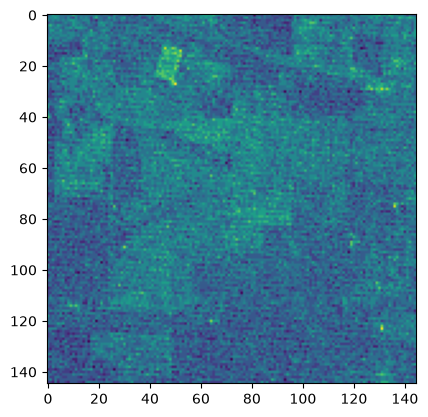

In [3]:
with rasterio.open(DATA_PATH) as src:
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("Data type:", src.dtypes)
    print("CRS:", src.crs)
    print("Compression:", src.compression)
    print("NoData:", src.nodata)

    plt.imshow(src.read(1))
    data = [src.read(i) for i in range(1, src.count+1)]

dict_keys(['__header__', '__version__', '__globals__', 'indian_pines_gt'])
(145, 145) uint8


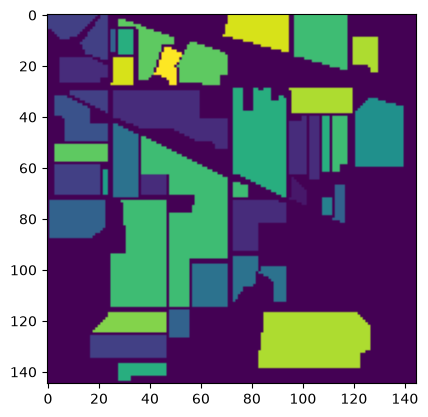

In [4]:
mat = loadmat(GT_PATH)
print(mat.keys())

gt = mat['indian_pines_gt']
print(gt.shape, gt.dtype)
plt.imshow(gt)

In [5]:
data_np = np.array(data)
X = data_np.transpose(1, 2, 0).reshape(-1, len(data_np))

y = np.array(gt).flatten()


In [6]:
mask = (y != 0)
X = X[mask]
y = y[mask]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

In [8]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear", C=1.0, gamma="scale", random_state=42)),
])

In [9]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[uint8](16,)","[ 1, 2, 3,...,14,15,16]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,220
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [10]:
# 3. Prediksi
y_pred = model.predict(X_test)

Akurasi: 0.8683

              precision    recall  f1-score   support

           1       0.75      0.86      0.80        14
           2       0.82      0.90      0.86       428
           3       0.88      0.73      0.80       249
           4       0.74      0.76      0.75        71
           5       0.90      0.92      0.91       145
           6       0.96      0.97      0.97       219
           7       0.88      0.88      0.88         8
           8       0.98      0.98      0.98       143
           9       0.67      0.33      0.44         6
          10       0.82      0.76      0.79       292
          11       0.84      0.86      0.85       737
          12       0.85      0.87      0.86       178
          13       0.98      0.98      0.98        61
          14       0.94      0.95      0.94       380
          15       0.77      0.74      0.76       116
          16       1.00      0.96      0.98        28

    accuracy                           0.87      3075
   macro 

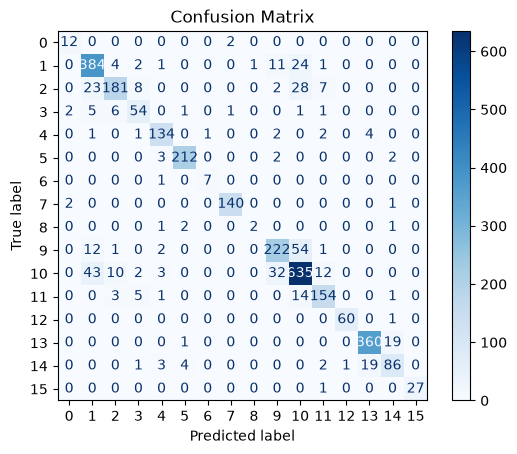

In [11]:
# 4. Evaluasi
print(f"Akurasi: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()